In [ ]:
import pandas as pd
import sklearn.preprocessing as lp
from sklearn.metrics import mean_absolute_error
import torch
import tqdm
import numpy as np

# Aceasta este functia de evaluare care calculeaza scorul T2, in functie de metrica MAE trimisa ca parametru.
# Puteti astfel sa intelegeti care ar trebui sa fie MAE-ul pentru care ar trebui sa obtineti un scor maxim.
def evaluate_t2_score(mae):
    # Interpolation such that at min_value you get score_min, at max_value you get score_max
    def lerp(value, min_value, max_value, score_min, score_max) -> int:
        slide = np.clip((value - min_value) / (max_value - min_value), 0.0, 1.0)
        score_res = score_min + (score_max - score_min) * slide
        return int(score_res)

    score = 0
    if mae >= 100:
        score = 0
    elif mae >= 20:
        score = lerp(mae, 100.0, 20.0, 0, 10)
    elif mae >= 10.0:
        score = lerp(mae, 20.0, 10.0, 10, 30)
    elif mae >= 8.0:
        score = lerp(mae, 10.0, 8.0, 30, 40)
    elif mae >= 5.0:
        score = lerp(mae, 8.0, 5.0, 40, 60)
    elif mae >= 4.5:
        score = lerp(mae, 5.0, 4.5, 60, 70)
    else:
        score = lerp(mae, 4.5, 4.3, 70, 80)

    return score, mae, score, mae


# Citirea datelor
train_df = pd.read_csv("train_data.csv")
predict_df = pd.read_csv("test_data.csv")

# Testam daca se incarca corect
print("Train DataFrame:", train_df.head())






Train DataFrame:    ID     City A     City B  Distance  Time of Day Weather     Traffic  \
0   1  Satu Mare    Suceava       352          452     Fog  154.014691   
1   2   Ploiesti  Timisoara       519         1386   Clear  949.697532   
2   3       Deva      Bacau       457           91     Fog  387.019309   
3   4  Hunedoara    Focsani       447         1120   Clear  130.544017   
4   5  Hunedoara       Arad       201         1096   Clear  619.557737   

   Road Quality  Driver Experience  deliver_time  
0           370                 30           355  
1           701                  2           529  
2            45                 26           465  
3           643                  6           441  
4           375                 20           230  


In [ ]:
y = (train_df.values.T)[9]


In [ ]:
matrix = train_df.values
n_train = len(matrix)
matrix = np.delete(matrix, [9], axis = 1)
matrix = np.vstack([matrix] + [predict_df.values])
keep = [row for row in matrix if not pd.isna(row).any()]
matrix = np.vstack(keep)
matrix = np.delete(matrix, [0], axis = 1)
cols = matrix.T




In [ ]:
add = []
for i in [0, 1, 4]:
    cols[i] = np.unique(cols[i], return_inverse=True)[1]
    col2 = cols[i].reshape(-1, 1)
    ohe = lp.OneHotEncoder(sparse_output=False)
    add.append(ohe.fit_transform(col2).T)

cols = np.delete(cols, [0, 1, 4], axis = 0)
add.append(np.ones_like(cols[0]))
cols = np.vstack([cols]+ add)

cols = cols.astype(float)
data = cols.T

print(cols)

[[3.52000000e+02 5.19000000e+02 4.57000000e+02 ... 1.10000000e+02
  3.76000000e+02 4.41000000e+02]
 [4.52000000e+02 1.38600000e+03 9.10000000e+01 ... 3.88000000e+02
  1.00200000e+03 1.00000000e+01]
 [1.54014691e+02 9.49697532e+02 3.87019309e+02 ... 4.93491538e+02
  6.89094462e+01 3.96628157e+01]
 ...
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.00000000e+00
  1.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.00000000e+00 1.00000000e+00 1.00000000e+00 ... 1.00000000e+00
  1.00000000e+00 1.00000000e+00]]


In [ ]:
X_train = data[:n_train]
X_test = data[n_train:]
X_train = X_train.astype(float)
mean = X_train.mean(axis=0)
std  = X_train.std(axis=0) + 1e-8
X_test = (X_test - mean) / std
X_train = (X_train - mean) / std
X_train[:, -1] = np.ones_like(X_train[:, -1])
X_test[:, -1] = np.ones_like(X_test[:, -1])

100%|██████████| 99/99 [00:09<00:00, 10.02it/s]


1.6479650831807655
[ 1.66624319e+02  2.89175095e+00  8.67687107e+00 -5.83414341e+00
 -5.92256996e+00  6.32119566e-02  3.49310430e-02 -2.81774887e-02
 -1.92248440e-02 -5.04568257e-02 -4.38217335e-02  3.17418255e-02
  7.25773230e-02  2.86126864e-02  1.18647218e-02  1.51999312e-02
  2.53659761e-02  5.72662063e-02 -1.59761715e-02 -4.86895993e-02
  1.41288676e-02 -5.22068663e-02  4.56276360e-02 -1.38951726e-03
 -7.12634951e-02 -2.04884665e-03  5.56124699e-03  8.41163686e-04
 -3.43800878e-02 -1.05306100e-02  3.10197684e-05 -9.12117796e-03
  5.56658533e-02 -5.71208013e-02 -1.50991946e-02  4.17851168e-02
  9.31617363e-02 -5.14976034e-02 -7.93871045e-02 -6.20497744e-03
 -5.57100531e-03  6.73861483e-03 -3.69291788e-02  7.82953265e-04
  2.31165476e-02  6.17109969e-02  1.50995348e-02  2.55196175e-02
 -6.12791488e-02 -7.68954245e-03  1.37422217e-02  2.84582210e-02
  4.80823946e-02 -4.07674234e-03  2.34193115e-02 -1.71261928e-02
 -3.03223633e-02  1.59041678e-02 -3.75444104e-03 -3.61589768e-03
  2.10

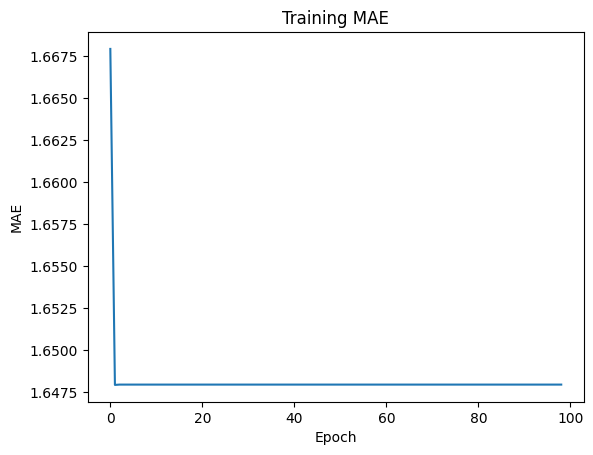

In [ ]:
import matplotlib.pyplot as plt
weight = np.zeros_like(X_train[0], dtype=float)
a = 1e-3
history = []
for i in tqdm.tqdm(range(1,100)):
    for j in range(len(X_train)):
        diff = -y[j] + np.dot(weight, X_train[j])
        weight -= a * diff * X_train[j]
    history.append(np.mean(abs(y - X_train @ weight)))

print(np.mean(abs(y - X_train @ weight)))
print(weight)
pd.Series(history).plot(title='Training MAE', xlabel='Epoch', ylabel='MAE')
plt.show()

In [ ]:
print(np.mean(abs(y - X_train @ weight)))

1.6479650831807655


In [ ]:
print(pd.read_csv('sample_output.csv').head())


   Unnamed: 0  subtaskID  datapointID  answer
0           0          1            1     0.0
1           1          2        10001   464.3
2           2          2        10002   245.5
3           3          2        10003   492.0
4           4          2        10004   274.4


In [ ]:
ans = X_test @ weight
fogcheck = predict_df.values
numfog  = 0
for i in range(len(fogcheck)):
    if(fogcheck[i][1] == "Barlad" and fogcheck[i][5] == "Fog"):
        numfog += 1

In [ ]:
# Subtask 1: one row
part1 = pd.DataFrame({'subtaskID': [1], 'datapointID': [1], 'answer': [numfog]})

# Subtask 2: one row per test trip
part2 = pd.DataFrame({'subtaskID': 2, 'datapointID': predict_df['ID'], 'answer': ans})

# Join them and save
out = pd.concat([part1, part2], ignore_index=True)
out.to_csv('output.csv', index=False)

print(out.head())
print(len(out), len(predict_df) + 1)

   subtaskID  datapointID      answer
0          1            1   15.000000
1          2        10001  387.258313
2          2        10002  242.814703
3          2        10003  480.647399
4          2        10004  248.062936
2001 2001
